<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [Statsmodels Regression](https://github.com/Query-farm/vgi-statsmodels)

Regression fits and hypothesis tests over SQL relations.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-statsmodels/blob/main/notebooks/02_odds_are_not_probability_changes.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-statsmodels/blob/main/notebooks/README.md)


## 02 · An odds ratio is not a probability change

How much does a one-hour increase in an input change the modeled chance of an event?
The logit coefficient answers on a **log-odds** scale. We fit the same synthetic binary
observations using `logit` and a binomial `glm`, reconstruct probabilities in SQL,
and compare an odds multiplier with a probability difference at several baselines.
Changing the input unit should change coefficients without changing fitted probabilities.

**Synthetic teaching data only.** No real people, clinical claims or operational
predictions. All fits use the full sample; no held-out predictive or causal validation
is claimed.

### Change the unit, keep the observations

`MINUTES_PER_UNIT` is **60** by default: one model-input unit is one hour.
The experiment uses **30**, so one unit is half an hour. The underlying input is
600 values from 0 to 240 minutes. Seed 2718 supplies uniform draws; the event generator
is `P(event=1) = logistic(-2 + 0.8 * minutes/60)`. All events, minutes and rows stay fixed.
This is a unit conversion, not a new population or intervention.

In [1]:
MINUTES_PER_UNIT = 60  # Experiment: 30; accepted integer range 15–120.

### Run this notebook

Read the saved output on GitHub or use **Open in Colab**, then Run All. The shared
base package preserves compatible preloaded plotting/data libraries. Initial downloads
need internet; all analytical inputs are deterministic synthetic data created locally.
The short Git-tag launcher installs the released worker in its own environment, using
its declared Python requirement. No credentials, cloned source or local worker build
are required. Actual hosted Colab has not been tested; a fresh preloaded Python 3.12
notebook-only execution exercises this installation and worker launch path.

In [2]:
import importlib.metadata as packages

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.24":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.24"
from vgi_notebooks import check_runtime

check_runtime()
if packages.version("vgi-example-notebooks") != "0.3.24":
    raise RuntimeError("Install shared tools v0.3.24, then restart and run all.")

In [3]:
import hashlib
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from vgi_notebooks.presentation import finish, prose, theme
from vgi_notebooks.session import connect

%matplotlib inline
theme()
session = connect(globals())
con = session.connection

if type(MINUTES_PER_UNIT) is not int or not 15 <= MINUTES_PER_UNIT <= 120:
    raise ValueError("MINUTES_PER_UNIT must be an integer from 15 to 120.")
draws = pd.DataFrame({"row_id": np.arange(600), "draw": np.random.default_rng(2718).uniform(size=600)})
draw_fingerprint = hashlib.sha256(draws.to_json(orient="records", double_precision=15).encode()).hexdigest()
con.register("draw_input", draws)
con.execute("CREATE TABLE draws AS SELECT * FROM draw_input")
con.unregister("draw_input")
families = coefficients = curves = contrasts = pd.DataFrame()

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'statsmodels' (TYPE vgi,
 LOCATION 'uvx --from git+https://github.com/Query-farm/vgi-statsmodels@v0.4.0 vgi-statsmodels');

,Success


### Let the outcome choose the family

The catalog's `glm_families` view describes four supported families. A binary outcome
calls for binomial with the logit link; a Poisson count family is a different model,
even when the response happens to be stored as an integer. Read the reference alongside
the observed outcome inventory before fitting.

In [5]:
%%sql
CREATE TABLE family_reference AS SELECT * FROM statsmodels.main.glm_families;
CREATE TABLE binary_data AS
WITH design AS (SELECT row_id,draw,240.0*row_id/599.0 AS minutes FROM draws),
truth AS (SELECT *,1.0/(1+exp(-(-2+0.8*minutes/60))) AS generating_probability FROM design)
SELECT *,minutes/{{MINUTES_PER_UNIT}} AS x,(draw<generating_probability)::INTEGER AS event FROM truth;
SELECT event,count(*) AS rows,min(minutes) AS min_minutes,max(minutes) AS max_minutes
FROM binary_data GROUP BY event ORDER BY event;

,event,rows,min_minutes,max_minutes
0,0,343,0.000000,237.996661
1,1,257,0.400668,240.000000


In [6]:
%%sql families <<
SELECT * FROM family_reference ORDER BY family;

In [7]:
display(families)
assert len(families) == 4
assert families.set_index("family").loc["binomial", "link"] == "logit"
assert con.execute("SELECT count(*)=600 AND count(DISTINCT event)=2 AND count(x)=600 FROM binary_data").fetchone()[0]
prose(
    "The **binomial / logit** reference row matches this binary event response. Both fits below use the same 600 complete observations and an intercept; only their public SQL entry point differs."
)

,family,link,typical_outcome,example_use
0,binomial,logit,Binary (0/1) or proportion outcomes,Yes/no events; the same fit as logit().
1,gamma,inverse,"Positive, right-skewed continuous outcomes","Durations, insurance claim sizes, spend."
2,gaussian,identity,"Continuous, roughly symmetric outcomes",Reproduces ordinary least squares (OLS).
3,poisson,log,Non-negative integer counts,Event counts such as purchases or arrivals.


The **binomial / logit** reference row matches this binary event response. Both fits below use the same 600 complete observations and an intercept; only their public SQL entry point differs.

### Fit the same model through two entry points

The `logit` result includes `odds_ratio = exp(coef)`. A binomial GLM with its default
logit link specifies the same mean model; its independent optimizer should return
matching coefficients and ordinary large-sample standard errors here. Agreement
checks the two interfaces for this example, not the validity of the model.
Each worker result is materialized once before local capture.

In [8]:
%%sql
CREATE TABLE logit_fit AS SELECT * FROM statsmodels.main.logit(
 (SELECT event,x FROM binary_data ORDER BY row_id),formula := 'event ~ x');
CREATE TABLE glm_fit AS SELECT * FROM statsmodels.main.glm(
 (SELECT event,x FROM binary_data ORDER BY row_id),formula := 'event ~ x',family := 'binomial');
CREATE TABLE comparison AS
SELECT l.term,l.coef,l.std_err,l.p_value,l.ci_lower,l.ci_upper,l.odds_ratio,
 g.coef AS glm_coef,g.std_err AS glm_std_err,l.coef-g.coef AS coefficient_difference
FROM logit_fit l JOIN glm_fit g USING(term);
SELECT * FROM comparison ORDER BY term;

,term,coef,std_err,p_value,ci_lower,ci_upper,odds_ratio,glm_coef,glm_std_err,coefficient_difference
0,Intercept,-1.982186,0.204504,3.240396e-22,-2.383007,-1.581365,0.137768,-1.982186,0.204504,-8.637535e-14
1,x,0.816193,0.085508,1.357408e-21,0.648602,0.983785,2.261873,0.816193,0.085508,3.463896e-14


In [9]:
%%sql coefficients <<
SELECT * FROM comparison ORDER BY term;

In [10]:
display(coefficients)
assert coefficients.term.tolist() == ["Intercept", "x"]
assert np.allclose(coefficients.coef, coefficients.glm_coef, atol=1e-7, rtol=1e-7)
assert np.allclose(coefficients.std_err, coefficients.glm_std_err, atol=1e-7, rtol=1e-7)
assert np.allclose(coefficients.odds_ratio, np.exp(coefficients.coef))
assert coefficients.p_value.between(0, 1).all()
slope = coefficients.set_index("term").loc["x"]
prose(
    f"The fitted coefficient is **{slope.coef:.4f} log-odds per {MINUTES_PER_UNIT}-minute unit**, giving an odds multiplier of **{slope.odds_ratio:.3f}**. This multiplier is not a percentage-point probability change. Both interfaces agree to numerical tolerance; the coefficient p-value still depends on the specified model and independent-observation assumptions."
)

,term,coef,std_err,p_value,ci_lower,ci_upper,odds_ratio,glm_coef,glm_std_err,coefficient_difference
0,Intercept,-1.982186,0.204504,3.240396e-22,-2.383007,-1.581365,0.137768,-1.982186,0.204504,-8.637535e-14
1,x,0.816193,0.085508,1.357408e-21,0.648602,0.983785,2.261873,0.816193,0.085508,3.463896e-14


The fitted coefficient is **0.8162 log-odds per 60-minute unit**, giving an odds multiplier of **2.262**. This multiplier is not a percentage-point probability change. Both interfaces agree to numerical tolerance; the coefficient p-value still depends on the specified model and independent-observation assumptions.

### Transform the returned coefficients, keeping units explicit

SQL reconstructs `1/(1+exp(-(intercept+slope*x)))` from each returned coefficient table.
The observed event fraction within each 30-minute bin is descriptive and uses the same
training rows. Its variation around the curve does not constitute a calibration test.

For a fixed **60-minute increase**, the odds multiplier is constant, but the probability
difference depends on where that hour begins. Only starts from 0 through 180 minutes
are used, keeping both endpoints within the observed range. No prediction intervals
are implied by the displayed curves.

In [11]:
%%sql
CREATE TABLE curve AS
WITH terms AS (
 SELECT 'Logit' AS model,max(coef) FILTER(WHERE term='Intercept') AS a,max(coef) FILTER(WHERE term='x') AS b FROM logit_fit
 UNION ALL SELECT 'Binomial GLM',max(coef) FILTER(WHERE term='Intercept'),max(coef) FILTER(WHERE term='x') FROM glm_fit
)
SELECT model,minutes,1.0/(1+exp(-(a+b*minutes/{{MINUTES_PER_UNIT}}))) AS probability
FROM terms CROSS JOIN (SELECT range::DOUBLE AS minutes FROM range(241));
CREATE TABLE binned AS SELECT least(floor(minutes/30),7)::INTEGER AS bin,
 avg(minutes) AS minutes,avg(event) AS observed_fraction,count(*) AS observations
FROM binary_data GROUP BY bin;
CREATE TABLE contrasts AS
WITH terms AS (SELECT max(coef) FILTER(WHERE term='Intercept') AS a,max(coef) FILTER(WHERE term='x') AS b FROM logit_fit),
points AS (SELECT range*30.0 AS start_minutes FROM range(7))
SELECT start_minutes,exp(b*60/{{MINUTES_PER_UNIT}}) AS hour_odds_multiplier,
 1.0/(1+exp(-(a+b*(start_minutes+60)/{{MINUTES_PER_UNIT}}))) -
 1.0/(1+exp(-(a+b*start_minutes/{{MINUTES_PER_UNIT}}))) AS hour_probability_change
FROM terms CROSS JOIN points;
SELECT * FROM contrasts ORDER BY start_minutes;

,start_minutes,hour_odds_multiplier,hour_probability_change
0,0.0,2.261873,0.116494
1,30.0,2.261873,0.147469
2,60.0,2.261873,0.175851
3,90.0,2.261873,0.195467
4,120.0,2.261873,0.201099
5,150.0,2.261873,0.191109
6,180.0,2.261873,0.168360


In [12]:
%%sql curves <<
SELECT * FROM curve ORDER BY model,minutes;

In [13]:
%%sql contrasts <<
SELECT * FROM contrasts ORDER BY start_minutes;

,start_minutes,hour_odds_multiplier,hour_probability_change
0,0.0,2.261873,0.116494
1,30.0,2.261873,0.147469
2,60.0,2.261873,0.175851
3,90.0,2.261873,0.195467
4,120.0,2.261873,0.201099
5,150.0,2.261873,0.191109
6,180.0,2.261873,0.168360


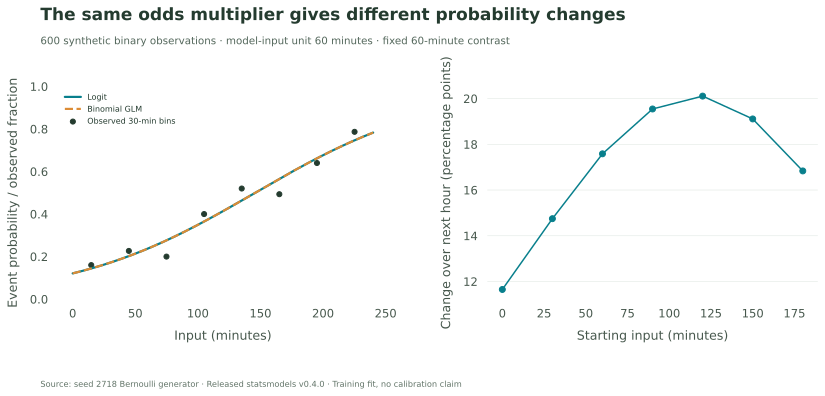

A fixed hour multiplies fitted odds by **2.262**, while its fitted probability change ranges from **11.6 to 20.1 percentage points** across the displayed baselines. Unit conversion must preserve both these hour-level contrasts and every fitted probability.

52255

In [14]:
display(contrasts)
bins = con.execute("SELECT * FROM binned ORDER BY bin").fetchdf()
assert curves.probability.between(0, 1).all() and len(curves) == 482
assert np.allclose(
    curves.query("model=='Logit'").probability, curves.query("model=='Binomial GLM'").probability, atol=1e-7
)
assert bins.observations.sum() == 600
assert np.allclose(contrasts.hour_odds_multiplier, contrasts.hour_odds_multiplier.iloc[0])
assert contrasts.hour_probability_change.max() > contrasts.hour_probability_change.min()
fig, axes = plt.subplots(1, 2, figsize=(12, 5.8))
for model, color, style in [("Logit", "#087F8C", "-"), ("Binomial GLM", "#DC8C36", "--")]:
    q = curves.loc[curves.model == model]
    axes[0].plot(q.minutes, q.probability, color=color, ls=style, lw=2.2, label=model)
axes[0].scatter(bins.minutes, bins.observed_fraction, color="#243B2F", s=26, label="Observed 30-min bins")
axes[0].set(xlabel="Input (minutes)", ylabel="Event probability / observed fraction", ylim=(0, 1))
axes[0].legend(fontsize=8, loc="upper left")
axes[1].plot(contrasts.start_minutes, 100 * contrasts.hour_probability_change, "o-", color="#087F8C")
axes[1].set(xlabel="Starting input (minutes)", ylabel="Change over next hour (percentage points)")
axes[1].grid(axis="y")
finish(
    fig,
    "The same odds multiplier gives different probability changes",
    f"600 synthetic binary observations · model-input unit {MINUTES_PER_UNIT} minutes · fixed 60-minute contrast",
    "Source: seed 2718 Bernoulli generator · Released statsmodels v0.4.0 · Training fit, no calibration claim",
    name=f"odds-probability-{MINUTES_PER_UNIT}",
)
prose(
    f"A fixed hour multiplies fitted odds by **{contrasts.hour_odds_multiplier.iloc[0]:.3f}**, while its fitted probability change ranges from **{100 * contrasts.hour_probability_change.min():.1f} to {100 * contrasts.hour_probability_change.max():.1f} percentage points** across the displayed baselines. Unit conversion must preserve both these hour-level contrasts and every fitted probability."
)
Path("artifacts").mkdir(exist_ok=True)
Path("artifacts/binary-audit.json").write_text(
    json.dumps(
        {
            "minutes_per_unit": MINUTES_PER_UNIT,
            "draw_fingerprint": draw_fingerprint,
            "coefficients": coefficients.to_dict("records"),
            "curves": curves.to_dict("records"),
            "contrasts": contrasts.to_dict("records"),
        },
        indent=2,
    )
)

### Experiment: halve the input unit

Change only `MINUTES_PER_UNIT` from **60 to 30** and rerun. The slope and its standard
error should halve; the one-unit odds ratio should become its former square root.
The intercept, p-values, confidence interval after conversion back to per-hour units,
all fitted probabilities and the 60-minute contrasts should stay unchanged to
numerical precision. Compare the audit fingerprints and figure as well as coefficients.

These are unpenalized fits with ordinary model-based uncertainty. Neither equivalent
optimizers nor a small p-value establishes a causal effect or validates predictions
outside this sample. See the primary [Logit documentation](https://www.statsmodels.org/stable/generated/statsmodels.discrete.discrete_model.Logit.html).

In [15]:
session.close()
plt.close("all")

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-statsmodels](https://github.com/Query-farm/vgi-statsmodels)